# OSM crop → Raster2Seq: walkthrough for one crop

Steps through what `data_preprocess/create_coco_osm.py` does for a single crop, and checks the result against the rendered map:

1. Load a crop (GeoJSON + PNG)
2. Extract geometries in PNG pixels, with vocabulary labels
3. Build COCO annotations
4. Convert to a Raster2Seq token sequence
5. Compare the shapes with the PNG

## Setup

Uses the `raster2seq` conda environment. Adds `../../Raster2Seq` (for its `datasets` module) and the repo root (for `data_preprocess`) to the path.

In [9]:
import sys
import gzip, json
import numpy as np
sys.path[:0] = ["../../Raster2Seq", ".."]

from data_preprocess.create_coco_osm import extract_geometries, make_to_px, build_annotations, CATEGORIES
from datasets.data_utils import plot_polygons
from datasets.poly_data import ConvertToCocoDictWithOrder_plus

from matplotlib import pyplot as plt
from matplotlib.patches import Polygon as MplPolygon
from PIL import Image
%matplotlib inline

## 1. Load a crop

Each crop is a pair in `../crops/`:
- `<name>.geojson.gz` – the vector features (OpenMapTiles schema) plus `bbox` and `metadata` (`source_zoom`, `camera_zoom`).
- `<name>.png` – the rendered map image.

In [19]:
name = "manhattan_05950"
with gzip.open(f"../crops/{name}.geojson.gz", "rt") as fh:
    data = json.load(fh)
img = Image.open(f"../crops/{name}.png")
W, H = img.size

In [20]:
data["bbox"], data["metadata"];

## 2. Extract geometries

`extract_geometries` converts each GeoJSON feature into `(points, label, geom_type)`:
- **points** – corners in PNG pixels. `make_to_px` converts lon/lat at the crop's `camera_zoom` (18) and scales to the PNG width (2× renders).
- **label** – from the fixed vocabulary (`VOCAB` / `CATEGORIES`), based on the OpenMapTiles layer and class, e.g. `street`, `building`, `park`. Anything unlisted becomes `unknown` / `unknown_line`.
- **geom_type** – `"polygon"` or `"line"`.

Details: MultiPolygons / MultiLineStrings are split into separate shapes, polygons keep only their outer ring (holes are ignored) and drop GeoJSON's repeated closing point, and label-only and administrative layers in `SKIP` are left out.

In [21]:
polygons = extract_geometries(data, make_to_px(data, W))   # pixels of the PNG
polygons

[([(484.0070508122444, 438.0176326557994),
   (463.98623971641064, 474.00617138296366),
   (357.99151729792356, 416.01094172149897),
   (366.00729827582836, 401.97982232272625),
   (316.0111945942044, 390.01644207537174),
   (236.0025156289339, 532.0012982264161),
   (273.99358919262886, 567.9897335469723),
   (282.00937017053366, 554.0079111158848),
   (388.00409258902073, 614.0213954299688),
   (367.98328149318695, 650.0097405090928),
   (133.99704235047102, 519.9887337088585),
   (152.00458751618862, 487.9880280122161),
   (158.0071025788784, 491.97580996900797),
   (165.9856008514762, 475.9754473268986),
   (154.01785343885422, 467.9998790323734),
   (217.99497045576572, 352.00929556787014),
   (230.00000056624413, 359.9848921597004),
   (238.01578154414892, 346.00298081338406),
   (232.01326648890972, 342.0151810646057),
   (251.9967948794365, 307.99578316509724)],
  'building',
  'polygon'),
 ([(1161.9929907247424, 689.9858038052917),
   (1171.9847549200058, 696.3859079256654),
 

## 3. Build COCO annotations

`build_annotations` turns each shape into a COCO annotation – the format Raster2Seq reads from `annotations/{split}.json`:
- **simplifies** each shape (Douglas-Peucker, `simplify_tol` in PNG pixels),
- **drops** polygons smaller than `min_area` (20 px² by default),
- **reorders** polygon corners to start at the top-left (lines keep their start → finish order),
- stores `segmentation` (flat `[x1, y1, x2, y2, …]`), `bbox`, `area`, `category_id` (from `CATEGORIES`) and `geom_type`.

In [22]:
anns = build_annotations(polygons, W, H, simplify_tol=1.0)   # tolerance in PNG pixels; labels from CATEGORIES

## 4. Convert to a Raster2Seq sequence

Run the same converter Raster2Seq's `MultiPoly` dataset uses during training (`ConvertToCocoDictWithOrder_plus`). It:
- sorts the shapes left to right,
- scales corners to 0–1 and snaps them to a `num_bins × num_bins` grid (with bilinear weights for the exact position),
- builds one token sequence: corners, a separator between shapes, and an end token.

Settings:
- `semantic_classes = len(CATEGORIES) + 1` – Raster2Seq reserves the last class ("undefined") for separator/end tokens.
- `seq_len = 1024` – shapes past this length are dropped without warning.

In [23]:
# same converter MultiPoly uses in training (sorts shapes, then builds the sequence)
conv = ConvertToCocoDictWithOrder_plus(
    root="../crops", augmentations=None, image_norm=False, poly2seq=True,
    semantic_classes=len(CATEGORIES) + 1,    # +1 for the "undefined" class used on separator tokens
    num_bins=64, seq_len=1024,
)
record = conv(0, f"{name}.png", anns)

### Decode the sequence

Split the sequence back into shapes at the separator / end tokens (`token_labels`: 0 = corner, 1 = separator, 2 = end) and plot them in sequence order (C1, C2, …).

`target_seq` holds exact 0–1 coordinates; the converter divides by `H - 1`, so multiplying by `H - 1` gives pixels again. Shapes that didn't fit in `seq_len` are missing here.

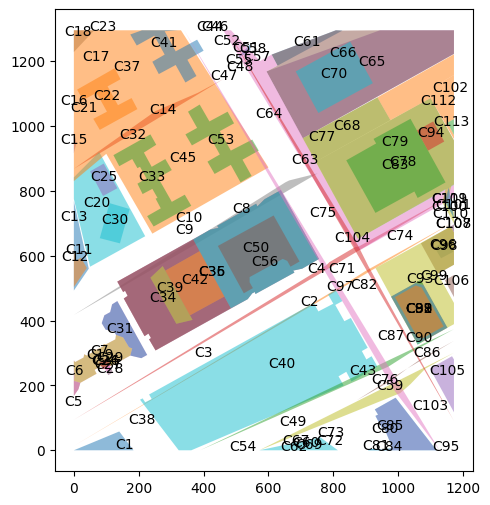

In [24]:
# decode the sequence back into shapes (in sequence order); token label 0 = point, else separator/end
n = int(record["mask"].sum())
seq_shapes, cur = [], []
for xy, t in zip(record["target_seq"][:n].tolist(), record["token_labels"][:n].tolist()):
    if t == 0:
        cur.append(xy)
    else:
        seq_shapes.append(cur)
        cur = []
plot_polygons([np.array(s) * (H - 1) for s in seq_shapes], "polys.png")   # converter normalized by H - 1

## 5. Compare the shapes with the PNG

Three panels, all in PNG pixel coordinates:
1. **rendered PNG** – the image Raster2Seq sees.
2. **shapes** – the annotations, coloured by label. Polygons are filled; lines are drawn open.
3. **overlay** – outlines on top of the PNG. If the conversion is right, they trace the buildings, streets, etc.

This shows every annotation, including any that were cut from the sequence in step 4.

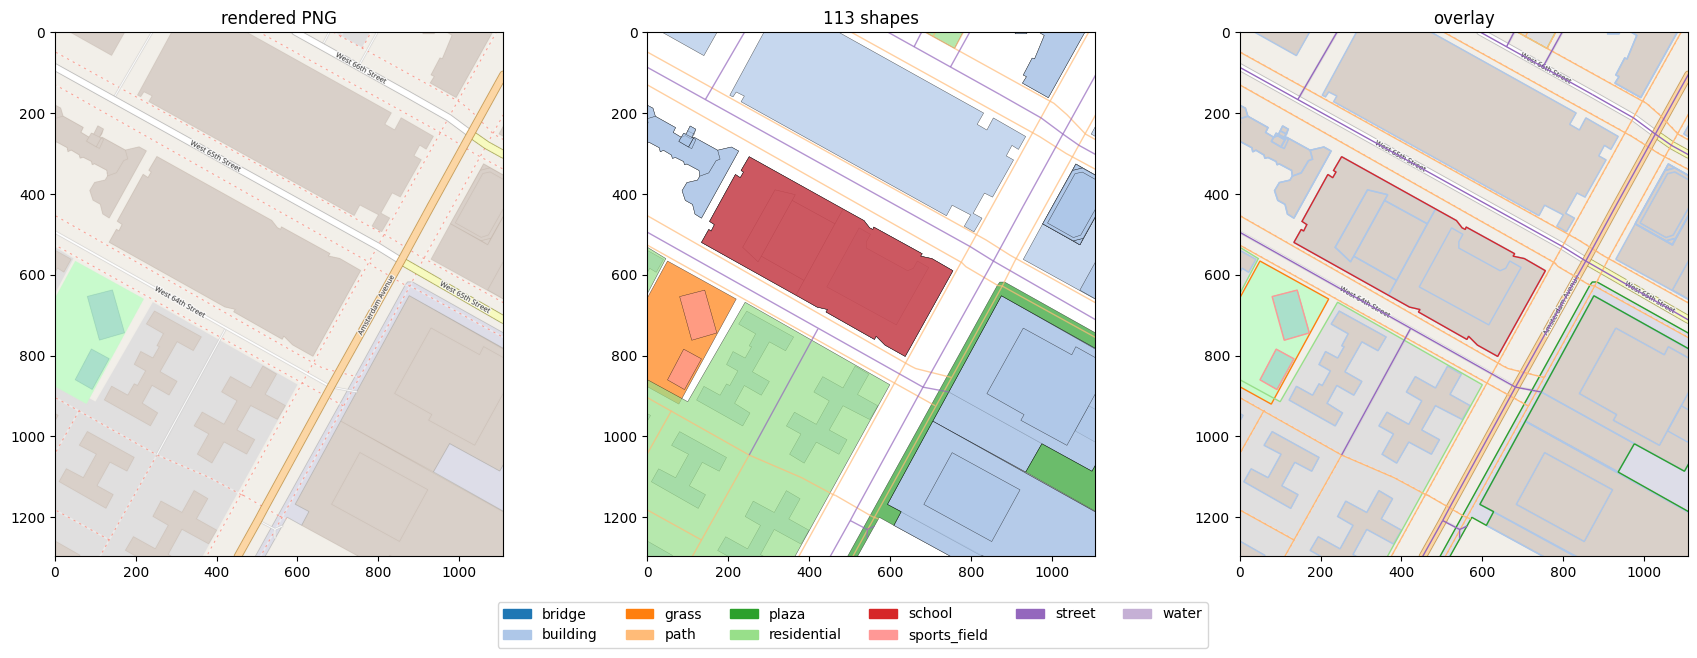

In [25]:
names = {i: n for n, i in CATEGORIES.items()}
present = sorted({names[a["category_id"]] for a in anns})              # labels in this crop
colors = {n: plt.cm.tab20(i % 20) for i, n in enumerate(present)}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for i, (ax, title) in enumerate(zip(axes, ["rendered PNG", f"{len(anns)} shapes", "overlay"])):
    if i != 1:
        ax.imshow(img, extent=(0, W, H, 0))
    ax.set(title=title, xlim=(0, W), ylim=(H, 0), aspect="equal")   # y increases downward, like the image

for a in anns:
    pts, c, is_poly = np.reshape(a["segmentation"][0], (-1, 2)), colors[names[a["category_id"]]], a["geom_type"] == "polygon"
    axes[1].add_patch(MplPolygon(pts, closed=is_poly, fill=is_poly, facecolor=c, edgecolor="black" if is_poly else c,
                                 linewidth=0.3 if is_poly else 1, alpha=0.7))
    axes[2].add_patch(MplPolygon(pts, closed=is_poly, fill=False, edgecolor=c, linewidth=1))

plt.tight_layout()
fig.legend([plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], list(colors),
           loc="upper center", bbox_to_anchor=(0.5, 0), ncol=6)   # below the plots
plt.show()